# Entrega 02 · Datos y preparación

**Pregunta:** ¿qué efecto tuvo la declaración de zonas de mercado residencial tensionado (Ley 12/2023) sobre la
renta del alquiler y el número de contratos nuevos registrados en Cataluña?

Este notebook recorre el flujo **Bronze → Silver → Gold** paso a paso y muestra las comprobaciones. Toda la lógica
vive en `src/preparacion_datos.py` (ejecutable también como script). El documento de la entrega es
`docs/entregas/02_datos_y_preparacion.md`.

**Fuentes:** registro de fianzas de alquiler del Incasòl (datos abiertos de la Generalitat, reutilización libre con atribución) y relación
oficial de municipios tensionados publicada en el BOE.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import preparacion_datos as prep

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})
COLORES = {"ola 1 (mar-2024)": "#2a78d6", "ola 2 (oct-2024)": "#e08a2c", "control (no tensionado)": "#52514e"}

## 1 · Bronze: adquisición reproducible

Se descarga el CSV completo del portal de datos abiertos (si no está ya en `data/raw/`) y se registra su huella
SHA-256. El fichero se conserva **tal cual llega**. Como la fuente se actualiza cada trimestre, el script avisa si
el fichero no coincide con la instantánea usada en esta entrega.

In [2]:
meta = prep.descargar_bronze(offline=True)
bronze = prep.leer_bronze()
print(json.dumps({k: meta[k] for k in ("sha256", "coincide_con_referencia", "bytes")}, indent=1))
print(f"Filas: {len(bronze):,}  |  Columnas: {list(bronze.columns)}")
bronze.head()

{
 "sha256": "602427170c393b4763e0118c48c1c5d52281d3eeea117750666fee8d7b6857a7",
 "coincide_con_referencia": true,
 "bytes": 4320656
}
Filas: 47,541  |  Columnas: ['Àmbit territorial', 'Codi territorial', 'Nom territori', 'Any', 'Període', 'Habitatges', 'Renda', 'Tram de preus']


,Àmbit territorial,Codi territorial,Nom territori,Any,Període,Habitatges,Renda,Tram de preus
0,Municipi,08001,Abrera,2026,gener-juny,62,"783,62",> 600 euros/mes
1,Municipi,25002,Àger,2026,gener-juny,7,"384,29",> 350 i <= 450 euros/mes
2,Municipi,25003,Agramunt,2026,gener-juny,39,"474,23",> 450 i <= 600 euros/mes
3,Municipi,17001,Agullana,2026,gener-juny,5,NaN,> 600 euros/mes
4,Municipi,08014,Aiguafreda,2026,gener-juny,23,"688,46",> 600 euros/mes


### Qué problemas trae el dato bruto

Antes de limpiar se cuantifica cada problema que justifica una regla de Silver.

In [3]:
b = bronze.rename(columns=prep.COLUMNAS)
print("Periodos mezclados en la misma tabla (trimestres, semestres, acumulados y año):")
print(b["periodo"].value_counts().to_string(), "\n")
print("Números en formato español (punto = miles):", b.loc[b["contratos"].str.contains(r"\.", na=False), "contratos"].head(3).tolist(),
      "| renta:", b["renta_media"].dropna().head(3).tolist())
print(f"Filas sin renta (solo tramo, por secreto estadístico): {b['renta_media'].isna().sum():,} ({b['renta_media'].isna().mean():.0%})")
cambios = b.groupby("codigo_ine")["municipio_fuente"].unique()
print("Municipios que cambian de nombre:", cambios[cambios.map(len) > 1].map(list).head(4).to_dict())
print("Tramos de renta (dos esquemas distintos según el año):", sorted(b["tramo_renta"].dropna().unique()))

Periodos mezclados en la misma tabla (trimestres, semestres, acumulados y año):
periodo
gener-desembre      15297
gener-juny           6163
gener-setembre       5757
gener-març           5458
abril-juny           5376
octubre-desembre     4745
juliol-setembre      4745 

Números en formato español (punto = miles): ['1.221', '16.001', '1.282'] | renta: ['783,62', '384,29', '474,23']
Filas sin renta (solo tramo, por secreto estadístico): 20,947 (44%)
Municipios que cambian de nombre: {'08023': ['Bigues i Riells del Fai', 'Bigues i Riells'], '08052': ["Castellar de N'Hug", "Castellar de n'Hug"], '17028': ['Brunyola i Sant Martí Sapresa', 'Brunyola'], '17034': ['Calonge i Sant Antoni', 'Calonge']}
Tramos de renta (dos esquemas distintos según el año): ['<= 350 euros/mes', '> 350 i <= 450 euros/mes', '> 350 i <= 500 euros/mes', '> 450 i <= 600 euros/mes', '> 500 i <= 650 euros/mes', '> 600 euros/mes', '> 650 euros/mes']


## 2 · Silver: tipos, formatos, periodos y coherencia

Reglas aplicadas (ver `a_silver`):

| Problema | Regla |
|---|---|
| Números con punto de miles y coma decimal | conversión explícita (`numero_es`) |
| Código INE sin cero inicial (`8019`) | rellenar a 5 dígitos (`08019`) |
| Periodos acumulados (`gener-juny`, `gener-setembre`) | se descartan: se reconstruyen con los trimestres |
| Mezcla de datos anuales y trimestrales | dos tablas: trimestral (2019+) y anual (2007+) |
| Renta suprimida en municipios con pocos contratos | se conserva la fila y se marca `renta_disponible` |
| Cambios de nombre | nombre canónico = el más reciente por código |
| Duplicados y valores imposibles | comprobación explícita (no aparece ninguno) |

In [4]:
trim, anual, log = prep.a_silver(bronze)
print(json.dumps(log, indent=1, ensure_ascii=False))
trim.head()

{
 "filas_bronze": 47541,
 "ambitos": {
  "Municipi": 47541
 },
 "filas_sin_renta": 20947,
 "duplicados_exactos": 0,
 "duplicados_clave": 0,
 "municipios_con_cambio_de_nombre": 10,
 "filas_implausibles": 0,
 "descartadas_periodos_acumulados": 11920,
 "coherencia_anual_vs_trimestral": {
  "municipio_anio_comparados": 3521,
  "coinciden_exactamente_pct": 99.97,
  "diferencia_mediana_pct": 0.0
 }
}


,codigo_ine,municipio,anio,trimestre,periodo_q,contratos,renta_media,renta_disponible,tramo_renta
0,08001,Abrera,2026,2,2026Q2,33,842.44,True,> 600 euros/mes
1,25002,Àger,2026,2,2026Q2,6,381.67,True,> 350 i <= 450 euros/mes
2,25003,Agramunt,2026,2,2026Q2,20,509.00,True,> 450 i <= 600 euros/mes
3,17001,Agullana,2026,2,2026Q2,3,NaN,False,> 600 euros/mes
4,08014,Aiguafreda,2026,2,2026Q2,14,653.40,True,> 600 euros/mes


La suma de los cuatro trimestres coincide con el dato anual en el 99,97 % de los municipio-año, así que
las dos tablas son coherentes entre sí.

## 3 · Variable de tratamiento: municipios declarados tensionados

La lista oficial se transcribió de las dos resoluciones del BOE a `data/referencia/municipios_tensionados.csv`
y se cruza **por nombre** con el Incasòl (que escribe `Bisbal d'Empordà, la` donde el BOE pone
`la Bisbal d'Empordà`). Los 271 municipios encuentran su código; si alguno fallase, el script se detiene.

In [5]:
trat, log_t = prep.tratamiento(b.assign(codigo_ine=b["codigo_ine"].str.zfill(5)))
print(log_t)
trat.groupby(["ola", "fecha_efectos"]).size()

{'municipios_tensionados_cruzados': 271, 'ola_1': 140, 'ola_2': 131}


ola  fecha_efectos
1    2024-03-16       140
2    2024-10-10       131
dtype: int64

## 4 · Gold: panel municipio × trimestre

Una fila = **un municipio en un trimestre** (2019T1 – último trimestre publicado). El panel es equilibrado: si la
fuente no publica un municipio en un trimestre, la fila existe con `fila_en_fuente = False` para que los huecos
sean visibles en lugar de desaparecer.

- **Variables de resultado:** `renta_media` (€/mes de los contratos nuevos) y `contratos` (nº de contratos nuevos registrados; no es una medida directa de la oferta, porque una caída puede deberse a menos anuncios o a un cambio en el tipo de contrato).
- **Tratamiento:** `ola` (0 control, 1 marzo 2024, 2 octubre 2024), `post`, `trimestres_desde_tratamiento` para el estudio de eventos.
  El trimestre en que entra en vigor la norma se marca como `trimestre_transicion`, y `fraccion_trimestre_vigente` dice qué parte de él estuvo vigente.
- **Controles de contexto:** `periodo_ley_catalana_2020` (tope autonómico anterior, anulado por el TC en 2022).
- **Calidad:** `renta_no_publicada` (la fuente da contratos pero suprime la renta), `trimestre_anomalo_fuente`.
- **Dos muestras:** `muestra_principal` (≥ 90 % de trimestres con renta, mirando todo el periodo) y `muestra_pre_tratamiento` (la misma regla, mirando solo 2019T1–2023T4).

In [6]:
gold, resumen = prep.a_gold(trim, trat)
print(json.dumps(resumen, indent=1, ensure_ascii=False))
gold[gold["codigo_ine"] == "08019"].tail(10)

{
 "filas": 28260,
 "municipios": 942,
 "trimestres": 30,
 "rango": "2019Q1 - 2026Q2",
 "filas_sin_dato_en_fuente_pct": 28.1,
 "filas_sin_renta_pct": 65.2,
 "filas_renta_no_publicada": 10498,
 "filas_trimestre_transicion": 271,
 "fraccion_vigente_transicion": {
  "1": 0.176,
  "2": 0.902
 },
 "municipios_por_grupo": {
  "control (no tensionado)": 671,
  "ola 1 (mar-2024)": 140,
  "ola 2 (oct-2024)": 131
 },
 "trimestres_anomalos_fuente": [
  "2026Q1"
 ],
 "umbral_cobertura_renta": 0.9,
 "muestra_principal_por_grupo": {
  "ola 1 (mar-2024)": 134,
  "ola 2 (oct-2024)": 87,
  "control (no tensionado)": 29
 },
 "muestra_principal_filas": 7500,
 "muestra_principal_pct_contratos": 95.6,
 "muestra_pre_tratamiento_por_grupo": {
  "ola 1 (mar-2024)": 135,
  "ola 2 (oct-2024)": 101,
  "control (no tensionado)": 30
 },
 "comparacion_muestras": {
  "control (no tensionado)": {
   "en_ambas": 29,
   "solo_principal": 0,
   "solo_pre_tratamiento": 1
  },
  "ola 1 (mar-2024)": {
   "en_ambas": 134,
 

,codigo_ine,municipio,periodo,fecha_trimestre,anio,trimestre,contratos,renta_media,tramo_renta,fila_en_fuente,renta_disponible,renta_no_publicada,log_renta,log_contratos,ola,grupo,fecha_efectos,trimestre_transicion,fraccion_trimestre_vigente,post,trimestres_desde_tratamiento,periodo_ley_catalana_2020,trimestre_anomalo_fuente,cobertura_renta,muestra_principal,cobertura_renta_pre,muestra_pre_tratamiento
560,08019,Barcelona,2024Q1,2024-01-01,2024,1,9825,1193.51,> 600 euros/mes,True,True,False,7.084654,9.192787,1,ola 1 (mar-2024),2024-03-16,True,0.176,False,-1.0,False,False,1.0,True,1.0,True
561,08019,Barcelona,2024Q2,2024-04-01,2024,2,7938,1131.80,> 600 euros/mes,True,True,False,7.031565,8.979543,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,0.0,False,False,1.0,True,1.0,True
562,08019,Barcelona,2024Q3,2024-07-01,2024,3,7484,1133.33,> 600 euros/mes,True,True,False,7.032915,8.920656,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,1.0,False,False,1.0,True,1.0,True
563,08019,Barcelona,2024Q4,2024-10-01,2024,4,7656,1117.39,> 600 euros/mes,True,True,False,7.018751,8.943376,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,2.0,False,False,1.0,True,1.0,True
564,08019,Barcelona,2025Q1,2025-01-01,2025,1,7615,1087.23,> 600 euros/mes,True,True,False,6.991388,8.938007,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,3.0,False,False,1.0,True,1.0,True
565,08019,Barcelona,2025Q2,2025-04-01,2025,2,7411,1135.55,> 600 euros/mes,True,True,False,7.034872,8.910856,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,4.0,False,False,1.0,True,1.0,True
566,08019,Barcelona,2025Q3,2025-07-01,2025,3,7855,1153.11,> 600 euros/mes,True,True,False,7.050218,8.969033,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,5.0,False,False,1.0,True,1.0,True
567,08019,Barcelona,2025Q4,2025-10-01,2025,4,7908,1160.99,> 600 euros/mes,True,True,False,7.057028,8.975757,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,6.0,False,False,1.0,True,1.0,True
568,08019,Barcelona,2026Q1,2026-01-01,2026,1,8156,1137.35,> 600 euros/mes,True,True,False,7.036456,9.006632,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,7.0,False,True,1.0,True,1.0,True
569,08019,Barcelona,2026Q2,2026-04-01,2026,2,7845,1140.89,> 600 euros/mes,True,True,False,7.039564,8.967759,1,ola 1 (mar-2024),2024-03-16,False,1.000,True,8.0,False,False,1.0,True,1.0,True


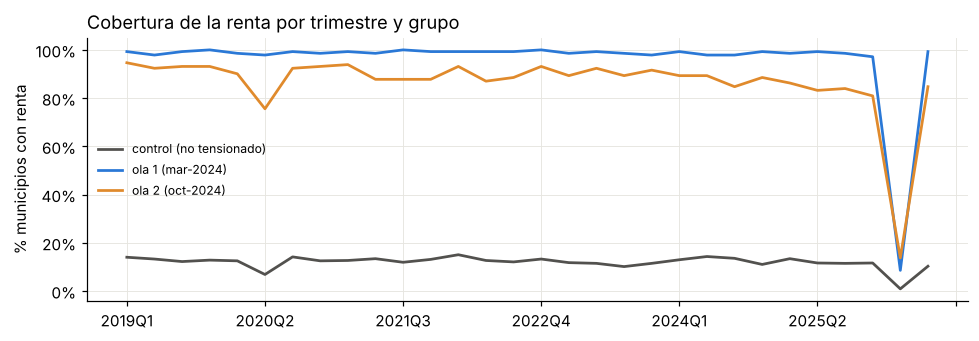

In [7]:
cob = gold.groupby(["periodo", "grupo"])["renta_disponible"].mean().unstack()
ax = cob.plot(figsize=(9, 3.2), color=[COLORES[c] for c in cob.columns], lw=1.8)
ax.set_title("Cobertura de la renta por trimestre y grupo", loc="left"); ax.set_ylabel("% municipios con renta"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Rentas no publicadas y trimestres de transición

Se marcan explícitamente las filas en las que el Incasòl da contratos pero no publica la renta, y los trimestres
en los que la medida solo estuvo vigente una parte del tiempo.

In [8]:
print(f"Filas con renta no publicada (hay contratos, falta la renta): {gold['renta_no_publicada'].sum():,}")
print(f"Filas sin el municipio en la fuente ese trimestre:             {(~gold['fila_en_fuente']).sum():,}")
gold[gold["trimestre_transicion"]].groupby(["grupo", "periodo"])["fraccion_trimestre_vigente"].agg(["first", "size"]).rename(columns={"first": "fracción vigente", "size": "municipios"})

Filas con renta no publicada (hay contratos, falta la renta): 10,498
Filas sin el municipio en la fuente ese trimestre:             7,936


,,fracción vigente,municipios
grupo,periodo,,
ola 1 (mar-2024),2024Q1,0.176,140
ola 2 (oct-2024),2024Q4,0.902,131


### Dos formas de elegir la muestra

La muestra principal se elige mirando todos los trimestres, también los posteriores a la medida. Si la ley
reduce los contratos de un municipio y por eso el Incasòl deja de publicar su renta, ese municipio saldría de la
muestra por el propio efecto que queremos medir. La muestra alternativa aplica la misma regla mirando solo
2019T1–2023T4.

In [9]:
pd.DataFrame(resumen["comparacion_muestras"]).T

,en_ambas,solo_principal,solo_pre_tratamiento
control (no tensionado),29,0,1
ola 1 (mar-2024),134,0,1
ola 2 (oct-2024),87,0,14


La caída de 2026T1 en los tres grupos es un problema de la fuente, no un cambio real: el resto de
trimestres cubre casi el 100 % de los municipios tensionados. Los municipios de control son en su mayoría
pequeños, con pocos contratos y la renta suprimida; por eso la muestra principal se queda con 29 de ellos.

### Primera mirada descriptiva (no es todavía el modelo)

Media de cada grupo, en índice (media de 2023 = 100), solo con la muestra principal. Sirve para ver si las
tendencias **antes** de 2024 son parecidas entre grupos, que es el supuesto clave del modelo de diferencias en
diferencias que se estimará en la fase siguiente.

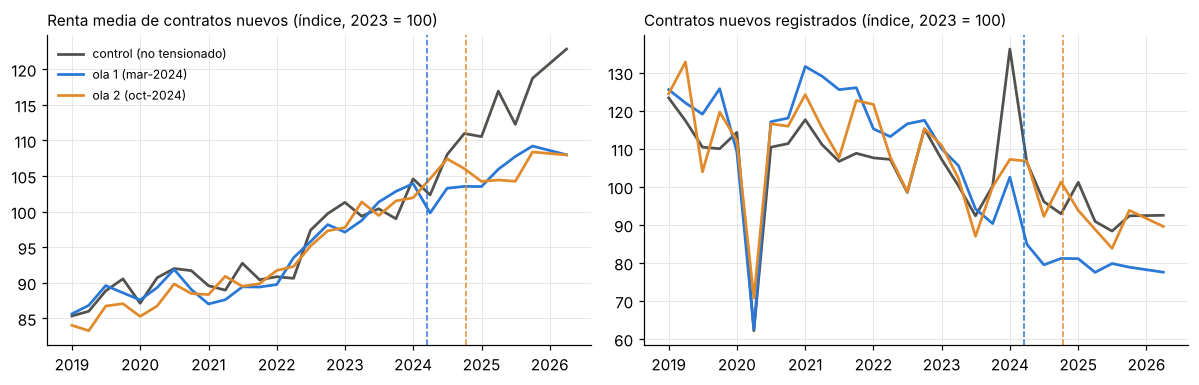

In [10]:
m = gold[gold["muestra_principal"] & ~gold["trimestre_anomalo_fuente"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, var, titulo in [(axes[0], "renta_media", "Renta media de contratos nuevos"), (axes[1], "contratos", "Contratos nuevos registrados")]:
    serie = m.groupby(["fecha_trimestre", "grupo"])[var].mean().unstack()
    base = serie[serie.index.year == 2023].mean()
    idx = serie / base * 100
    for g in idx.columns:
        ax.plot(idx.index, idx[g], color=COLORES[g], lw=1.8, label=g)
    ax.axvline(pd.Timestamp("2024-03-16"), color=COLORES["ola 1 (mar-2024)"], ls="--", lw=1)
    ax.axvline(pd.Timestamp("2024-10-10"), color=COLORES["ola 2 (oct-2024)"], ls="--", lw=1)
    ax.set_title(titulo + " (índice, 2023 = 100)", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5 · Guardar salidas

`main()` encadena todo y escribe Silver, Gold, el informe de calidad y las muestras pequeñas que sí se suben al
repositorio (`data/sample/`).

In [11]:
informe = prep.main(offline=True)
for p in sorted((ROOT / "data").glob("*/*")):
    if p.is_file() and p.suffix in {".parquet", ".csv", ".json"}:
        print(f"{p.relative_to(ROOT)}  ({p.stat().st_size/1024:,.0f} KB)")

data/gold/informe_calidad.json  (3 KB)
data/gold/panel_municipio_trimestre.parquet  (266 KB)
data/raw/bronze_metadata.json  (1 KB)
data/raw/incasol_fianzas_municipi.csv  (4,219 KB)
data/referencia/municipios_tensionados.csv  (25 KB)
data/sample/bronze_muestra.csv  (21 KB)
data/sample/gold_muestra.csv  (48 KB)
data/silver/fianzas_anual.parquet  (127 KB)
data/silver/fianzas_trimestral.parquet  (163 KB)


## Diccionario del Gold (`data/gold/panel_municipio_trimestre.parquet`)

| Columna | Significado |
|---|---|
| `codigo_ine` | Código INE del municipio (5 dígitos) |
| `municipio` | Nombre (el más reciente en la fuente) |
| `periodo`, `fecha_trimestre`, `anio`, `trimestre` | Trimestre de inicio de los contratos |
| `contratos` | Nº de contratos nuevos registrados (fianza depositada en el Incasòl) |
| `renta_media` | Renta media mensual de esos contratos (€) |
| `tramo_renta` | Tramo de renta publicado cuando la media se suprime |
| `fila_en_fuente`, `renta_disponible` | Si la fuente publica la fila / la renta |
| `renta_no_publicada` | La fuente da contratos pero suprime la renta (secreto estadístico) |
| `log_renta`, `log_contratos` | Transformaciones para el modelo (log y log(1+x)) |
| `ola`, `grupo` | 0 = control, 1 = tensionado desde 16/03/2024, 2 = desde 10/10/2024 |
| `fecha_efectos` | Fecha de entrada en vigor de la declaración |
| `trimestre_transicion` | Trimestre de entrada en vigor (tratado solo en parte) |
| `fraccion_trimestre_vigente` | Parte del trimestre con la medida vigente (0–1) |
| `post` | Trimestre completamente tratado |
| `trimestres_desde_tratamiento` | Tiempo relativo para el estudio de eventos (0 = primer trimestre tratado) |
| `periodo_ley_catalana_2020` | 2020T4–2022T1: tope autonómico anterior (Ley 11/2020) |
| `trimestre_anomalo_fuente` | Trimestre con la renta ausente por un problema de la fuente |
| `cobertura_renta` | % de trimestres con renta del municipio |
| `muestra_principal` | Municipio con cobertura ≥ 90 % en todo el periodo: base del análisis |
| `cobertura_renta_pre` | % de trimestres con renta en 2019T1–2023T4 |
| `muestra_pre_tratamiento` | Municipio con cobertura ≥ 90 % solo antes de la medida: muestra alternativa |